In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style='whitegrid')

In [3]:
df_income = pd.read_csv('../data/processed/01_income_statement.csv')
df_balance = pd.read_csv('../data/processed/02_balance_sheet.csv')
df_cashflow = pd.read_csv('../data/processed/03_cash_flow.csv')
df_stock = pd.read_csv('../data/processed/04_stock_price.csv')
df_ib = pd.read_csv('../data/processed/05_income_balance_merged.csv')

In [4]:
print(f'Income Statement Shape: {df_income.shape}')
print(f'Balance Sheet Shape: {df_balance.shape}')
print(f'Cash Flow Shape: {df_cashflow.shape}')
print(f'Stock Price Shape: {df_stock.shape}')

Income Statement Shape: (5, 28)
Balance Sheet Shape: (5, 29)
Cash Flow Shape: (5, 20)
Stock Price Shape: (15, 8)


In [5]:
df_income.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   fiscal_year                      5 non-null      str    
 1   period_ending                    5 non-null      str    
 2   revenue_eur_m                    5 non-null      int64  
 3   revenue_growth_pct               5 non-null      float64
 4   cost_of_revenue_eur_m            5 non-null      int64  
 5   gross_profit_eur_m               5 non-null      float64
 6   sg_a_eur_m                       5 non-null      float64
 7   depreciation_amortization_eur_m  5 non-null      float64
 8   total_operating_expenses_eur_m   5 non-null      int64  
 9   operating_income_eur_m           5 non-null      float64
 10  pretax_income_eur_m              5 non-null      float64
 11  income_tax_eur_m                 5 non-null      float64
 12  net_income_eur_m                 5 no

In [6]:
print("\n--- MISSING VALUES BY COLUMN (income statement) ---")
print(df_income.isnull().sum()[df_income.isnull().sum() > 0])


--- MISSING VALUES BY COLUMN (income statement) ---
net_income_growth_pct    2
eps_growth_pct           2
dtype: int64


In [7]:
print("\n--- DESCRIPTIVE STATS: KEY INCOME METRICS ---")
print(df_income[['revenue_eur_m', 'net_income_eur_m', 'operating_margin_pct', 'profit_margin_pct']].describe().round(2))


--- DESCRIPTIVE STATS: KEY INCOME METRICS ---
       revenue_eur_m  net_income_eur_m  operating_margin_pct  \
count           5.00              5.00                  5.00   
mean        11702.60           1355.24                  9.62   
std          4222.79            948.80                  9.48   
min          4801.00           -240.80                 -7.07   
25%         10775.00           1314.00                 11.17   
50%         13444.00           1612.00                 13.39   
75%         13949.00           1917.00                 15.27   
max         15544.00           2174.00                 15.33   

       profit_margin_pct  
count               5.00  
mean                9.39  
std                 8.14  
min                -5.02  
25%                11.55  
50%                12.19  
75%                13.98  
max                14.26  


In [8]:
colors = df_income['is_outlier_year'].map({True: 'red', False: 'steelblue'})

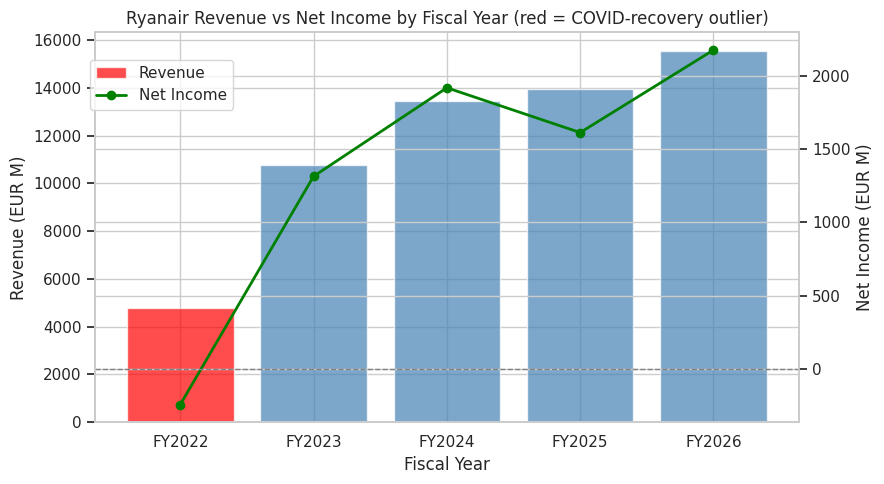

In [9]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.bar(df_income['fiscal_year'], df_income['revenue_eur_m'], color=colors, alpha=0.7, label='Revenue')
ax1.set_ylabel('Revenue (EUR M)')
ax1.set_xlabel('Fiscal Year')
 
ax2 = ax1.twinx()
ax2.plot(df_income['fiscal_year'], df_income['net_income_eur_m'], color='green', marker='o', linewidth=2, label='Net Income')
ax2.set_ylabel('Net Income (EUR M)')
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)
 
plt.title('Ryanair Revenue vs Net Income by Fiscal Year (red = COVID-recovery outlier)')
fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.88))
plt.tight_layout()
plt.savefig('../reports/figures/eda_01_revenue_vs_net_income.png', dpi=120)
plt.show()

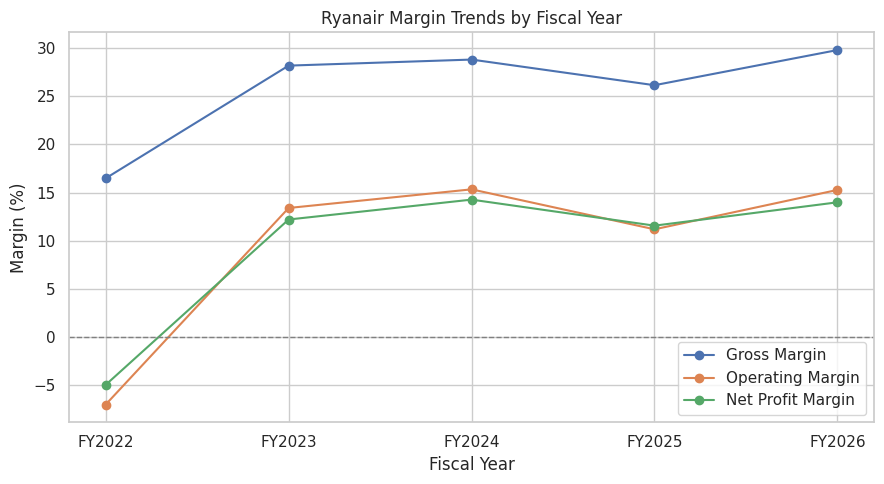

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(df_income['fiscal_year'], df_income['gross_margin_pct'], marker='o', label='Gross Margin')
plt.plot(df_income['fiscal_year'], df_income['operating_margin_pct'], marker='o', label='Operating Margin')
plt.plot(df_income['fiscal_year'], df_income['profit_margin_pct'], marker='o', label='Net Profit Margin')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Ryanair Margin Trends by Fiscal Year')
plt.xlabel('Fiscal Year')
plt.ylabel('Margin (%)')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/figures/eda_02_margin_trends.png', dpi=120)
plt.show()

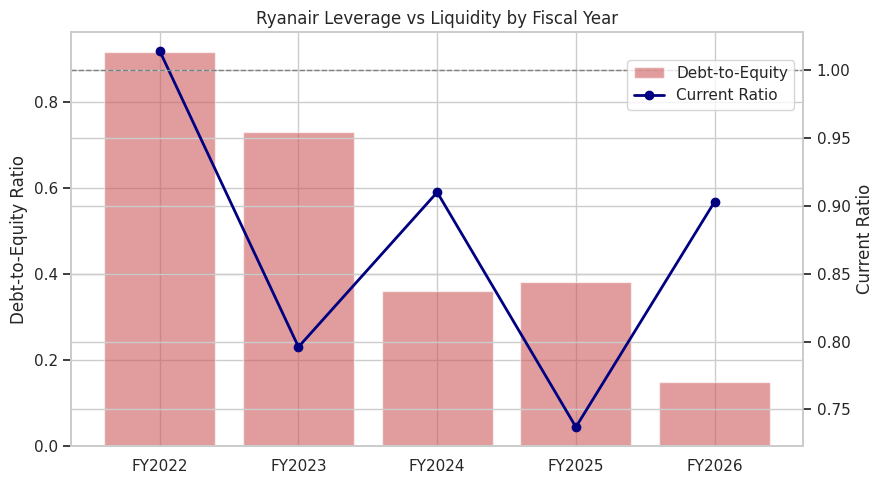

In [11]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.bar(df_balance['fiscal_year'], df_balance['debt_to_equity'], color='indianred', alpha=0.6, label='Debt-to-Equity')
ax1.set_ylabel('Debt-to-Equity Ratio')
 
ax2 = ax1.twinx()
ax2.plot(df_balance['fiscal_year'], df_balance['current_ratio'], color='navy', marker='o', linewidth=2, label='Current Ratio')
ax2.axhline(1, color='gray', linestyle='--', linewidth=1)   # current ratio of 1 = break-even liquidity
ax2.set_ylabel('Current Ratio')
 
plt.title('Ryanair Leverage vs Liquidity by Fiscal Year')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.savefig('../reports/figures/eda_03_leverage_vs_liquidity.png', dpi=120)
plt.show()

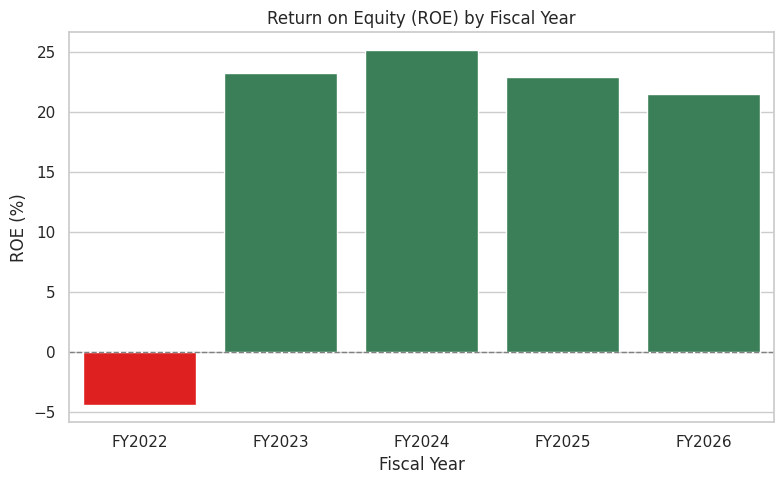

In [12]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_ib, x='fiscal_year', y='roe_pct', hue='is_outlier_year_is', palette={True: 'red', False: 'seagreen'}, legend=False)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Return on Equity (ROE) by Fiscal Year')
plt.xlabel('Fiscal Year')
plt.ylabel('ROE (%)')
plt.tight_layout()
plt.savefig('../reports/figures/eda_04_roe_trend.png', dpi=120)
plt.show()

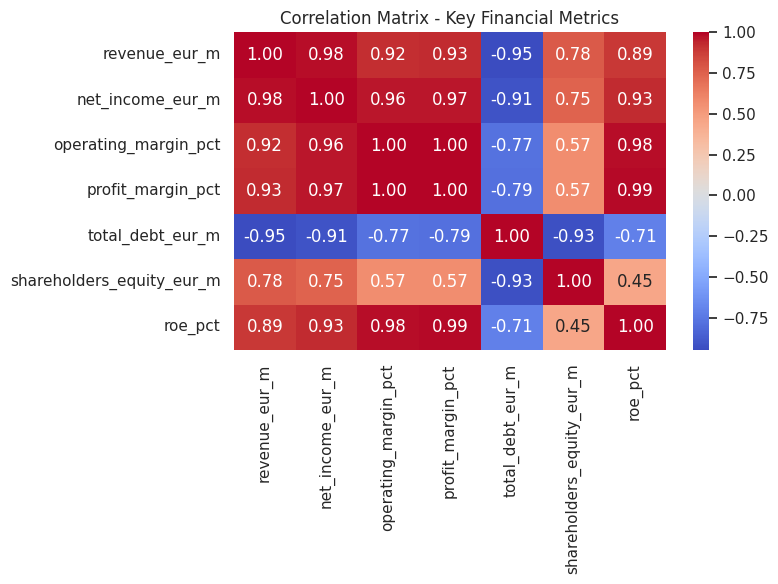

In [13]:
corr_cols = ['revenue_eur_m', 'net_income_eur_m', 'operating_margin_pct', 'profit_margin_pct',
             'total_debt_eur_m', 'shareholders_equity_eur_m', 'roe_pct']
corr_matrix = df_ib[corr_cols].corr()
 
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix - Key Financial Metrics')
plt.tight_layout()
plt.savefig('../reports/figures/eda_05_correlation_heatmap.png', dpi=120)
plt.show()

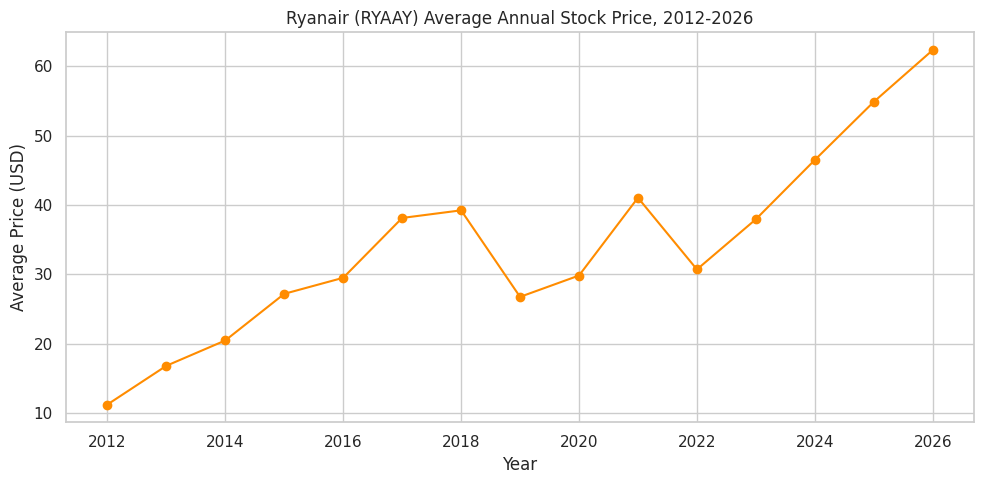

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(df_stock['year'], df_stock['average_price_usd'], marker='o', color='darkorange')
plt.title('Ryanair (RYAAY) Average Annual Stock Price, 2012-2026')
plt.xlabel('Year')
plt.ylabel('Average Price (USD)')
plt.tight_layout()
plt.savefig('../reports/figures/eda_06_stock_price_trend.png', dpi=120)
plt.show()

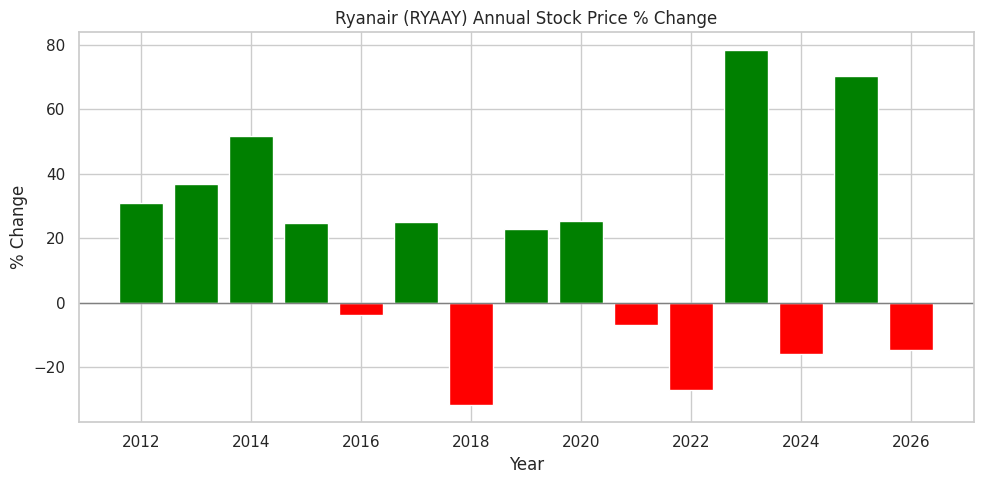

In [15]:
colors_stock = df_stock['annual_pct_change'].apply(lambda x: 'green' if x >= 0 else 'red')
plt.figure(figsize=(10, 5))
plt.bar(df_stock['year'], df_stock['annual_pct_change'], color=colors_stock)
plt.axhline(0, color='gray', linewidth=1)
plt.title('Ryanair (RYAAY) Annual Stock Price % Change')
plt.xlabel('Year')
plt.ylabel('% Change')
plt.tight_layout()
plt.savefig('../reports/figures/eda_07_stock_annual_change.png', dpi=120)
plt.show()

In [16]:
print("\n--- EDA QUICK TAKEAWAYS ---")
print(f"Revenue grew every year except the FY2022 COVID-recovery dip")
print(f"Debt-to-equity fell from {df_balance['debt_to_equity'].iloc[0]} in FY2022 to {df_balance['debt_to_equity'].iloc[-1]} in FY2026")
print(f"ROE has stayed in the 21-25% range since FY2023, well above the FY2022 outlier")
print(f"Strongest stock year: {df_stock.loc[df_stock['annual_pct_change'].idxmax(), 'year']} ({df_stock['annual_pct_change'].max()}%)")
print(f"Weakest stock year: {df_stock.loc[df_stock['annual_pct_change'].idxmin(), 'year']} ({df_stock['annual_pct_change'].min()}%)")


--- EDA QUICK TAKEAWAYS ---
Revenue grew every year except the FY2022 COVID-recovery dip
Debt-to-equity fell from 0.916 in FY2022 to 0.148 in FY2026
ROE has stayed in the 21-25% range since FY2023, well above the FY2022 outlier
Strongest stock year: 2023 (78.38%)
Weakest stock year: 2018 (-31.53%)
